In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Cargar dataset local
housing = pd.read_csv("../datasets/housing.csv")

# 2. Preprocesamiento Express (Para que no fallen los modelos)
# A) Borrar filas con huecos (NaN)
housing = housing.dropna()

# B) Separar X (Variables) e y (Objetivo)
y = housing["median_house_value"]
X_raw = housing.drop("median_house_value", axis=1)

# C) Convertir texto a números (One-Hot Encoding automático)
# Esto convierte 'ocean_proximity' en columnas de 0s y 1s
X = pd.get_dummies(X_raw, drop_first=True)

print(f"Datos listos para el torneo: {X.shape}")
X.head()

Datos listos para el torneo: (20433, 12)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,False,False,True,False
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,False,False,True,False
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,False,False,True,False
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,False,False,True,False
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,False,False,True,False


In [2]:
from sklearn.model_selection import cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# 1. Definir los Gladiadores
modelos = []
modelos.append(('Regresión Lineal', LinearRegression()))
modelos.append(('Árbol Decisión', DecisionTreeRegressor(random_state=42)))
modelos.append(('Random Forest', RandomForestRegressor(n_estimators=50, random_state=42)))

# 2. Ejecutar el Torneo
resultados = []
nombres = []
scoring = 'neg_root_mean_squared_error' # Queremos RMSE (Sklearn lo usa negativo por convención)

print(f"{'MODELO':<20} | {'RMSE PROMEDIO':<15} | {'DESVIACIÓN'}")
print("-" * 55)

for nombre, modelo in modelos:
    # Configurar el árbitro (10 validaciones)
    kfold = KFold(n_splits=10, shuffle=True, random_state=42)
    
    # ¡A correr!
    cv_results = cross_val_score(modelo, X, y, cv=kfold, scoring=scoring)
    
    # Convertimos a positivo para leerlo como "Error en Dólares"
    rmse_scores = -cv_results
    
    resultados.append(rmse_scores)
    nombres.append(nombre)
    
    print(f"{nombre:<20} | {rmse_scores.mean():,.0f}          | {rmse_scores.std():,.0f}")

MODELO               | RMSE PROMEDIO   | DESVIACIÓN
-------------------------------------------------------
Regresión Lineal     | 68,811          | 2,571
Árbol Decisión       | 68,130          | 2,340
Random Forest        | 48,633          | 1,730


C:\Users\magal\AppData\Local\Temp\ipykernel_16256\3523164353.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(resultados, labels=nombres, patch_artist=True)


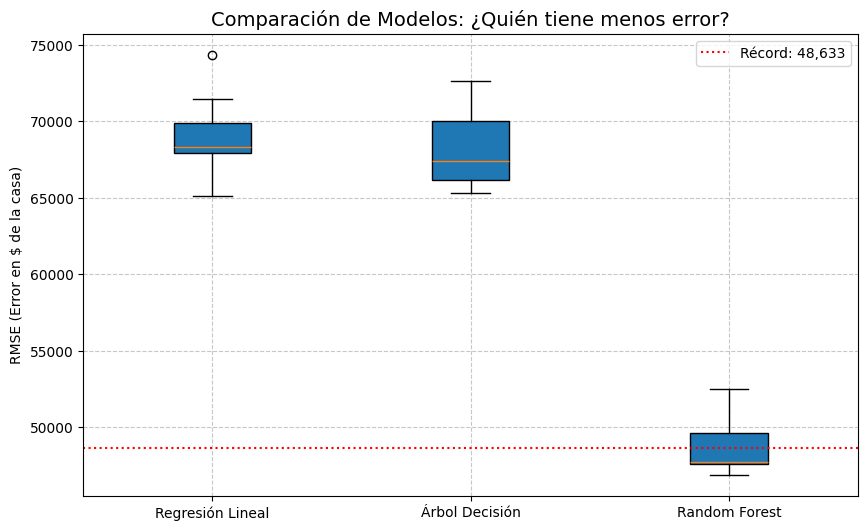

In [3]:
# Gráfico de Cajas (Boxplot)
plt.figure(figsize=(10, 6))
plt.boxplot(resultados, labels=nombres, patch_artist=True)
plt.title('Comparación de Modelos: ¿Quién tiene menos error?', fontsize=14)
plt.ylabel('RMSE (Error en $ de la casa)')
plt.grid(True, linestyle='--', alpha=0.7)

# Añadir línea del mejor promedio para referencia visual
mejor_promedio = np.mean(resultados[2]) # Asumiendo que Random Forest (índice 2) gana
plt.axhline(y=mejor_promedio, color='r', linestyle=':', label=f'Récord: {mejor_promedio:,.0f}')
plt.legend()

plt.show()